In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

### Task 1 Data Cleaning & Preprocessing

**Step 1: Import and load**

In [2]:
# Load the dataset (keep Dataset.csv in the same folder as this notebook)
df = pd.read_csv("Dataset.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
df.shape

(8790, 10)

In [4]:
df.type.value_counts()

type
Movie      6126
TV Show    2664
Name: count, dtype: int64

**Step 2: Find missing and duplicate records**

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [6]:
df.describe()

,release_year
count,8790.000000
mean,2014.183163
std,8.825466
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [7]:
df.title.unique()

array(['Dick Johnson Is Dead', 'Ganglands', 'Midnight Mass', ...,
       'Zindagi Gulzar Hai', 'Yoko', 'YOM'], dtype=object)

In [8]:
df.title.value_counts()

title
9-Feb                   2
15-Aug                  2
22-Jul                  2
YOM                     1
Dick Johnson Is Dead    1
                       ..
This Is My Love         1
The Underwear           1
Tientsin Mystic         1
Tip the Mouse           1
Samudri Lootere         1
Name: count, Length: 8787, dtype: int64

In [9]:
df.director.value_counts().head(20)

director
Not Given                       2588
Rajiv Chilaka                     20
Alastair Fothergill               18
Raúl Campos, Jan Suter            18
Marcus Raboy                      16
Suhas Kadav                       16
Jay Karas                         14
Cathy Garcia-Molina               13
Youssef Chahine                   12
Jay Chapman                       12
Martin Scorsese                   12
Steven Spielberg                  11
Don Michael Paul                  10
Mark Thornton, Todd Kauffman      10
David Dhawan                       9
Ryan Polito                        8
Troy Miller                        8
Fernando Ayllón                    8
Shannon Hartman                    8
Robert Rodriguez                   8
Name: count, dtype: int64

In [10]:
df.rating.value_counts()

rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

**Step 2: Find missing and duplicate records**

In [11]:
df.isnull().sum()

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [12]:
(df == "Not Given").sum()

show_id            0
type               0
title              0
director        2588
country          287
date_added         0
release_year       0
rating             0
duration           0
listed_in          0
dtype: int64

In [13]:
# Finding Duplicated rows
df.duplicated().sum()

np.int64(0)

In [14]:
df["show_id"].duplicated().sum()

np.int64(0)

**Step 3: Handle nulls and inconsistent formats**

In [15]:
# Standardize placeholder values while preserving the fact that the information is unknown.
df["director"] = df["director"].replace("Not Given", "Unknown")
df["country"] = df["country"].replace("Not Given", "Unknown")

In [16]:
df[["title"]]

,title
0,Dick Johnson Is Dead
1,Ganglands
2,Midnight Mass
3,Confessions of an Invisible Girl
4,Sankofa
...,...
8785,Yunus Emre
8786,Zak Storm
8787,Zindagi Gulzar Hai
8788,Yoko


In [17]:
df["title"] = df["title"].str.strip()

In [18]:
# Parse dates safely; malformed or missing dates become NaT instead of stopping the notebook.
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8790 non-null   object        
 1   type          8790 non-null   object        
 2   title         8790 non-null   object        
 3   director      8790 non-null   object        
 4   country       8790 non-null   object        
 5   date_added    8790 non-null   datetime64[ns]
 6   release_year  8790 non-null   int64         
 7   rating        8790 non-null   object        
 8   duration      8790 non-null   object        
 9   listed_in     8790 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(8)
memory usage: 686.8+ KB


 **Step 4: Transform categorical and date columns (feature engineering)**

In [20]:
# Segrigating Year & Month from "date_added feature
df["year_added"] = df["date_added"].dt.year

In [21]:
df["month_added"] = df["date_added"].dt.month

In [22]:
df["month_name"] = df["date_added"].dt.month_name()

In [23]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year_added,month_added,month_name
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,September
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,September
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,September
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,September
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,September


In [24]:
df.duration.unique()

array(['90 min', '1 Season', '91 min', '125 min', '9 Seasons', '104 min',
       '87 min', '127 min', '76 min', '71 min', '131 min', '39 min',
       '36 min', '34 min', '35 min', '46 min', '67 min', '65 min',
       '61 min', '166 min', '103 min', '97 min', '106 min', '2 Seasons',
       '4 Seasons', '147 min', '94 min', '161 min', '111 min', '110 min',
       '105 min', '96 min', '124 min', '116 min', '98 min', '115 min',
       '122 min', '55 min', '99 min', '88 min', '100 min', '6 Seasons',
       '3 Seasons', '23 min', '102 min', '93 min', '95 min', '85 min',
       '83 min', '182 min', '5 Seasons', '92 min', '84 min', '48 min',
       '145 min', '119 min', '80 min', '128 min', '143 min', '273 min',
       '117 min', '114 min', '118 min', '108 min', '37 min', '121 min',
       '63 min', '142 min', '113 min', '154 min', '120 min', '82 min',
       '109 min', '101 min', '86 min', '77 min', '229 min', '15 min',
       '89 min', '156 min', '112 min', '107 min', '129 min', '44 min',
  

In [25]:
# Extract numeric duration safely; missing or malformed durations become NaN.
df["duration_value"] = pd.to_numeric(
    df["duration"].astype("string").str.extract(r"(\d+)")[0],
    errors="coerce"
)

In [26]:
df.duration_value.unique()

<IntegerArray>
[ 90,   1,  91, 125,   9, 104,  87, 127,  76,  71,
 ...
 196, 167, 178, 228,  18, 205, 201, 191,  10, 312]
Length: 210, dtype: Int64

In [27]:
df["duration_unit"] = df["duration"].str.extract(r"\d+\s+(\w+)")

**Task 1 — Final validation and export**

This cell verifies the cleaned data and exports a separate CSV for submission. The original dataset is not overwritten.

In [28]:
# Check duplicates and missing values after transformations.
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate show_id values:", df["show_id"].duplicated().sum())
print("\nRemaining null values:")
display(df.isna().sum().to_frame("missing_count"))

# Remove duplicate show IDs only if any exist.
df = df.drop_duplicates(subset=["show_id"], keep="first").copy()

# Save the processed dataset in a portable format.
df.to_csv("netflix_cleaned.csv", index=False)
print("Saved cleaned dataset to netflix_cleaned.csv")
print("Cleaned shape:", df.shape)

Duplicate rows: 0
Duplicate show_id values: 0

Remaining null values:


,missing_count
show_id,0
type,0
title,0
director,0
country,0
date_added,0
release_year,0
rating,0
duration,0
listed_in,0


Saved cleaned dataset to netflix_cleaned.csv
Cleaned shape: (8790, 15)


### Task 2: Exploratory Data Analysis (EDA)

**Step 1: Structure and statistics**

In [29]:
df.describe()

,date_added,release_year,year_added,month_added,duration_value
count,8790,8790.000000,8790.000000,8790.000000,8790.0
mean,2019-05-17 21:44:01.638225408,2014.183163,2018.873606,6.655859,69.934471
min,2008-01-01 00:00:00,1925.000000,2008.000000,1.000000,1.0
25%,2018-04-06 00:00:00,2013.000000,2018.000000,4.000000,2.0
50%,2019-07-03 00:00:00,2017.000000,2019.000000,7.000000,88.5
75%,2020-08-19 18:00:00,2019.000000,2020.000000,10.000000,106.0
max,2021-09-25 00:00:00,2021.000000,2021.000000,12.000000,312.0
std,NaN,8.825466,1.573568,3.436103,50.794433


In [30]:
df.nunique()

show_id           8790
type                 2
title             8786
director          4528
country             86
date_added        1713
release_year        74
rating              14
duration           220
listed_in          513
year_added          14
month_added         12
month_name          12
duration_value     210
duration_unit        3
dtype: int64

**Step 2: Content distribution by type**

type
Movie      6126
TV Show    2664
Name: count, dtype: int64


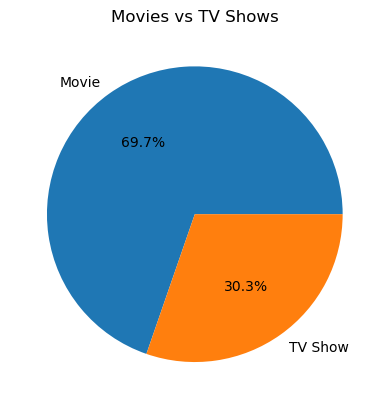

In [31]:
print(df["type"].value_counts())

df["type"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Movies vs TV Shows")
plt.ylabel("")
plt.show()

**Step 3: Top countries and categories**

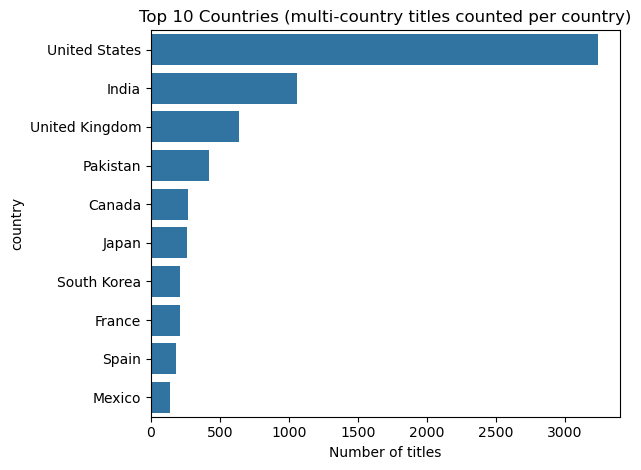

In [32]:
# Split multi-country cells so each country is counted separately.
country_values = (
    df.loc[df["country"].notna() & df["country"].ne("Unknown"), "country"]
      .astype(str).str.split(", ").explode().str.strip()
)
top_countries = country_values.value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 Countries (multi-country titles counted per country)")
plt.xlabel("Number of titles")
plt.tight_layout()
plt.show()

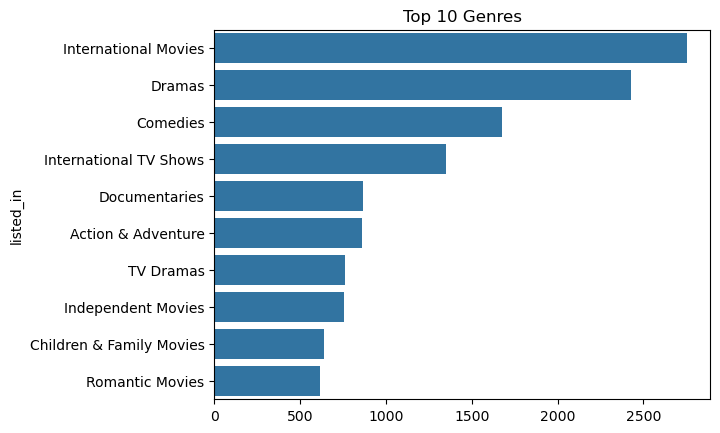

In [33]:
# Top 10 genres
genres = df['listed_in'].str.split(', ').explode()
top_genres = genres.value_counts().head(10)
sns.barplot(x=top_genres.values, y=top_genres.index)
plt.title("Top 10 Genres")
plt.show()

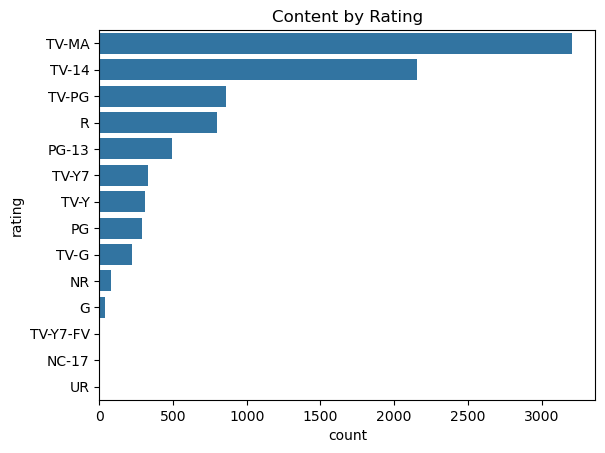

In [34]:
sns.countplot(data=df, y='rating', order=df['rating'].value_counts().index)
plt.title("Content by Rating")
plt.show()

**Step 4: Visualizations for key metrics**

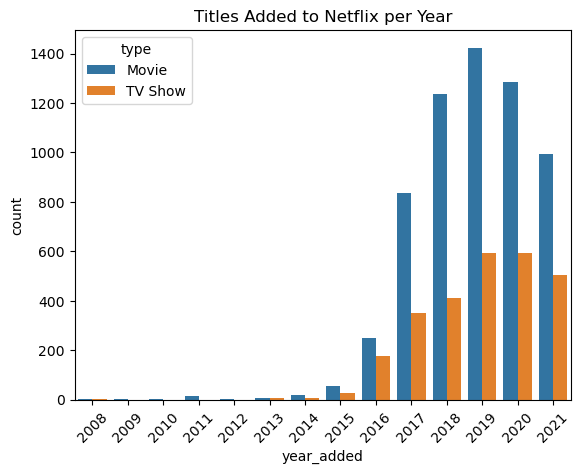

In [35]:
# Content added per year, split by type
sns.countplot(data=df, x="year_added", hue="type")
plt.xticks(rotation=45)
plt.title("Titles Added to Netflix per Year")
plt.show()

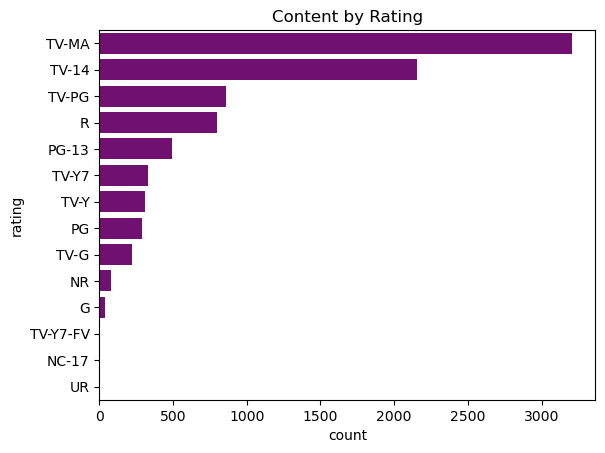

In [36]:
# Ratings
sns.countplot(data=df, y="rating", order=df["rating"].value_counts().index, color="purple")
plt.title("Content by Rating")
plt.show()

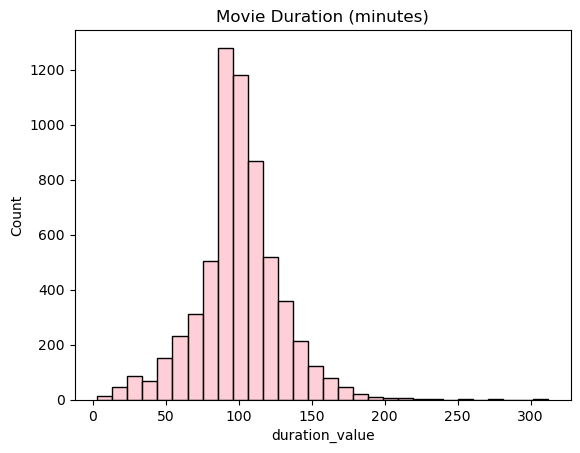

In [37]:
# Movie length distribution
sns.histplot(df[df["type"] == "Movie"]["duration_value"], bins=30, color="pink")
plt.title("Movie Duration (minutes)")
plt.show()

### Task 3: Recommendation System

**Step 1: Extract relevant features**

In [38]:
# Build metadata for the content-based recommender.
# Fill missing values before concatenation to avoid NaN values in the text.
recommender_columns = ["listed_in", "director", "country", "rating", "release_year"]
for col in recommender_columns:
    df[col] = df[col].fillna("")

df["features"] = df[recommender_columns].astype(str).agg(" ".join, axis=1)
df[["title", "features"]].head()

,title,features
0,Dick Johnson Is Dead,Documentaries Kirsten Johnson United States PG...
1,Ganglands,"Crime TV Shows, International TV Shows, TV Act..."
2,Midnight Mass,"TV Dramas, TV Horror, TV Mysteries Mike Flanag..."
3,Confessions of an Invisible Girl,"Children & Family Movies, Comedies Bruno Garot..."
4,Sankofa,"Dramas, Independent Movies, International Movi..."


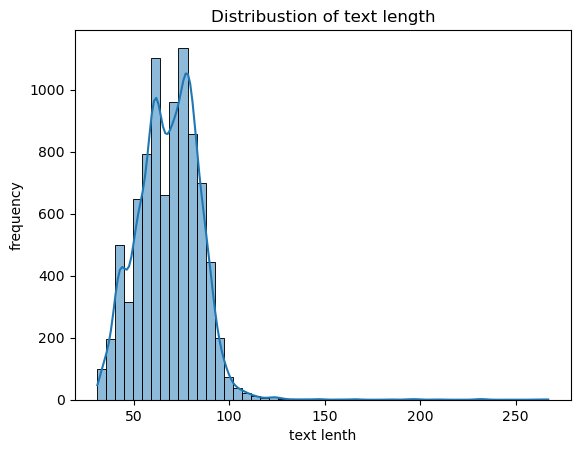

In [39]:
sns.histplot(df["features"].apply(len), bins=50, kde=True)
plt.title("Distribustion of text length")
plt.xlabel("text lenth")
plt.ylabel("frequency")
plt.show()

**Step 2: Text preprocessing**

In [40]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
import warnings
warnings.filterwarnings("ignore")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\marri\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\marri\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\marri\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\marri\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [41]:
def clean(doc):
    """Normalize metadata text for TF-IDF."""
    doc = str(doc)
    doc = re.sub(r"[^a-zA-Z0-9.]", " ", doc)
    doc = doc.lower()
    tokens = nltk.word_tokenize(doc)

    stop_words = set(stopwords.words("english"))
    stop_words.update(["unknown", "not", "given"])
    filtered_tokens = [word for word in tokens if word not in stop_words]

    lemmatizer = WordNetLemmatizer()
    return " ".join(lemmatizer.lemmatize(token) for token in filtered_tokens)

**Step 3–5: Similarity, recommendations, and a basic quality check**

The recommender uses TF-IDF and cosine similarity over catalogue metadata. Since this dataset has no user clicks, ratings, or watch history, recommendations can be inspected for metadata relevance but cannot be evaluated using user engagement metrics.

In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Clean the metadata and calculate TF-IDF vectors.
recommender_tfidf = TfidfVectorizer(preprocessor=clean, max_features=30000)
recommender_matrix = recommender_tfidf.fit_transform(df["features"])
similarity_matrix = cosine_similarity(recommender_matrix, dense_output=False)

def recommend_titles(title, top_n=5):
    """Return the top-N most similar titles for an exact title in the dataset."""
    matches = df.index[df["title"].astype(str).str.casefold() == str(title).casefold()].tolist()
    if not matches:
        print(f"Title not found: {title}")
        return pd.DataFrame(columns=["title", "type", "release_year", "similarity"])
    idx = matches[0]
    scores = similarity_matrix[idx].toarray().ravel()
    ranked_indices = scores.argsort()[::-1]
    rows = []
    for j in ranked_indices:
        if j == idx:
            continue
        rows.append({
            "title": df.iloc[j]["title"],
            "type": df.iloc[j]["type"],
            "release_year": df.iloc[j]["release_year"],
            "similarity": round(float(scores[j]), 3)
        })
        if len(rows) == top_n:
            break
    return pd.DataFrame(rows)

# Try an actual title from the dataset so the example always works.
example_title = df["title"].dropna().iloc[0]
print("Selected title:", example_title)
display(recommend_titles(example_title, top_n=5))

# Simple sanity check: output should contain up to five different titles, not the query title itself.
recommendation_check = recommend_titles(example_title, top_n=5)
assert example_title not in recommendation_check["title"].values
assert recommendation_check["title"].nunique() == len(recommendation_check)
print("Recommendation sanity check passed.")

Selected title: Dick Johnson Is Dead


,title,type,release_year,similarity
0,The Debt Collector 2,Movie,2020,0.399
1,S.W.A.T.,Movie,2003,0.397
2,Crip Camp: A Disability Revolution,Movie,2020,0.393
3,Murder to Mercy: The Cyntoia Brown Story,Movie,2020,0.383
4,"Love, Guaranteed",Movie,2020,0.380


Recommendation sanity check passed.


### Task 5: Machine Learning Classification

In [43]:
# Classification target is the content type: Movie or TV Show.
# IMPORTANT: duration is excluded because "90 min" / "1 Season" can reveal the target directly.
classification_features = ["listed_in", "director", "country", "rating", "release_year"]
X = df[classification_features].fillna("").astype(str).agg(" ".join, axis=1)
y = df["type"].astype(str)

print("Target distribution:")
print(y.value_counts())

Target distribution:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64


In [44]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

**Step 2: Train/test split**

In [45]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

**Step 3: NLP Train classification models**

In [46]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Naive Bayes": MultinomialNB(),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=200, class_weight="balanced")
}

results = {}
trained_models = {}
for name, clf in models.items():
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(preprocessor=clean, max_features=20000)),
        ("clf", clf)
    ])
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    results[name] = accuracy_score(y_test, pipeline.predict(X_test))

results_df = pd.DataFrame(
    [{"Model": name, "Test Accuracy": score} for name, score in results.items()]
).sort_values("Test Accuracy", ascending=False)
display(results_df)
best_model_name = results_df.iloc[0]["Model"]
model = trained_models[best_model_name]
print("Selected model:", best_model_name)

,Model,Test Accuracy
0,Logistic Regression,0.994881
2,Random Forest,0.986348
1,Naive Bayes,0.980660


Selected model: Logistic Regression


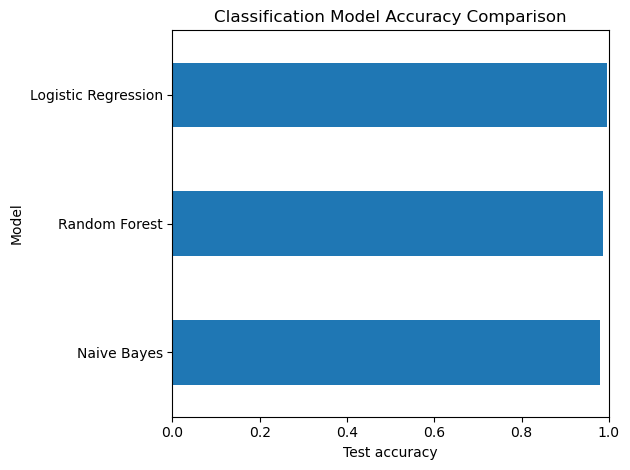

In [47]:
results_df.set_index("Model")["Test Accuracy"].sort_values().plot(
    kind="barh", title="Classification Model Accuracy Comparison", xlim=(0, 1)
)
plt.xlabel("Test accuracy")
plt.tight_layout()
plt.show()

In [48]:
# Evaluate the best model selected using the held-out test set.
y_pred = model.predict(X_test)

**Step 4 & 5: Evaluate performance & Compare model accuracy**

In [49]:
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))

Test accuracy: 0.9949


In [50]:
y_pred_train = model.predict(X_train)

In [51]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [52]:
print("Training accuracy:", round(accuracy_score(y_train, y_pred_train), 4))

Training accuracy: 0.9984


In [53]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       Movie       0.99      1.00      1.00      1225
     TV Show       1.00      0.99      0.99       533

    accuracy                           0.99      1758
   macro avg       1.00      0.99      0.99      1758
weighted avg       0.99      0.99      0.99      1758



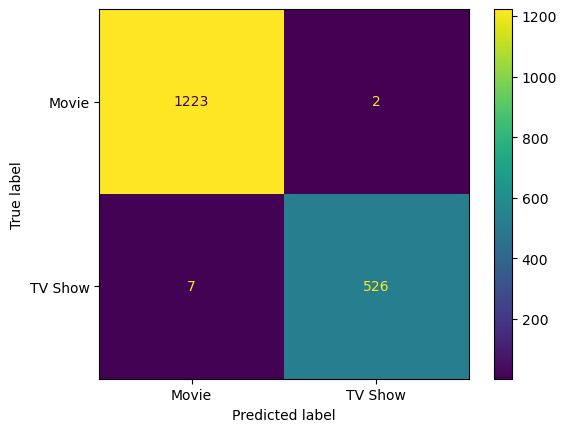

In [54]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

In [55]:
df.loc[8300, "features"]

'Anime Series, International TV Shows, Romantic TV Shows Unknown Japan TV-14 2014'

In [56]:
df.loc[1, ["features", "type"]]

features    Crime TV Shows, International TV Shows, TV Act...
type                                                  TV Show
Name: 1, dtype: object

In [57]:
df.loc[839,"features"]

'Dramas, Thrillers Mark Raso United States TV-MA 2021'

In [58]:
import pickle

In [59]:
# Save with a descriptive filename (this is a Netflix content-type model, not an email model).
with open("netflix_content_type_model.pkl", "wb") as file:
    pickle.dump(model, file)

In [60]:
with open("netflix_content_type_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

In [61]:
sample_metadata = "Anime Series, International TV Shows, Romantic TV Shows Unknown Japan TV-14 2019"
print("Predicted type:", loaded_model.predict([sample_metadata])[0])

Predicted type: TV Show


In [62]:
sample_metadata = "Documentaries Kirsten Johnson United States PG-13 2019"
print("Predicted type:", loaded_model.predict([sample_metadata])[0])

Predicted type: Movie


In [63]:
sample_metadata = "Dramas, Thrillers Mark Raso United States TV-MA 2020"
print("Predicted type:", loaded_model.predict([sample_metadata])[0])

Predicted type: Movie


In [64]:
import sklearn
print(sklearn.__version__)

1.6.1


## Final Findings, Limitations, and Submission Notes

### Findings to report
- Use the output of `df["type"].value_counts()` to report the Movie/TV Show distribution.
- Use the top-country and top-genre charts to describe the most represented catalogue segments.
- Use the model comparison table, classification report, and confusion matrix to report classification performance.

### Limitations
- The dataset is a catalogue snapshot and does not contain user viewing behaviour or engagement labels.
- The recommendation system is metadata-based, so its quality is assessed with sample relevance checks rather than click-through or ranking metrics.
- The classification target is `type`. Avoid using `duration` as a feature because duration format can leak the target label.
- A high test score does not by itself prove generalization; report the held-out metrics honestly.

### Submission checklist
1. Run all cells from top to bottom in a clean environment.
2. Ensure `Dataset.csv` is in the same folder as the notebook.
3. Submit the notebook, `netflix_cleaned.csv`, and screenshots of the charts/model results.
4. Add a GitHub repository link if available. A demo video is optional according to the task PDF.